In [1]:
# PLEASE NOTE - THERE ARE TWO NOTEBOOKS IN LAB 3!

# This notebook is for working through some classifier comparison techniques
# it corresponds to Lecture Handouts 3 and 4.
#
# The questions are:
#  -- Section 1: binary (two-class) classification (Lab 3 Ex. 1)  --
#   i) Evaluate & compare the ROC curves for different classifiers.
#  ii) Influence the classifier performance by introducing class weights.
#
#  -- Section 2: multi-class classification (Lab 3 Ex. 2) --
# iii) Evaluate & compare classifiers using the confusion matrix.
#  iv) Classifier selection with practical criteria.

# 📘 Lab 3 Ex. 1 study guide: comparing binary classifiers with ROC curves (handouts 03 & 04)

**Big picture.** Lab 2 built one classifier and measured it with accuracy. In practice you must (a) choose between **many** classifier families (handout-03) and (b) evaluate them with metrics that reflect what matters, for example *never missing a malignant tumour* (handout-04). This notebook does both.

**Concept map**

| Concept | Handout | Where |
|---|---|---|
| k-NN, decision trees, (linear / kernel) SVM, logistic regression | 03 slides 3–13, 17–31 (RBF kernel slide 28) | `classifiers` dict |
| No Free Lunch: no classifier is best on every problem | 03 slides 15–16 | synthetic vs real results |
| TP / FP / TN / FN, confusion matrix | 04 slides 6–9 | all metrics |
| Recall (TPR), precision, FPR, accuracy, F1 | 04 slides 11–13 | `show_classifier_metrics` |
| Threshold trade-off, ROC curve, AUC | 04 slides 14–23 | `evaluate_classifiers_ROC`, `plot_ROCs` |
| Class imbalance and misclassification costs | 04 slides 14–17 | class weights, Q2 |
| Train / test separation | 04 slides 34–37 | 50/50 splits |

**Key formulas** (positive class = 1):
$$\text{TPR}=\text{recall}=\frac{TP}{TP+FN},\quad \text{FPR}=\frac{FP}{FP+TN},\quad \text{precision}=\frac{TP}{TP+FP},\quad F_1=\frac{2\,\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

**Questions** (answers go in `lab_3.py`, which already contains them):

| Q | Asks | Answer in `lab_3.py` |
|---|---|---|
| 1 | highest TPR at FPR = 15% (synthetic data) | `"Nearest Neighbors"` |
| 2 | linear-SVM class weight that minimises FPR at total recall | `1.35` |

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')
%cd /content/gdrive/MyDrive/4c16-labs/code/dist/lab-03/

Mounted at /content/gdrive
/content/gdrive/MyDrive/4c16-labs/code/dist/lab-03


In [3]:
# Autoload setup (you don't need to edit this cell); instructions to:
import importlib
import lab_3

In [4]:
%%javascript
// This cell disables scrollbars on our output, which is handier when we want to do lots of plots.
// Don't edit this cell!
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [5]:
##############################################################
#
# Import useful libraries
#
# As well as numpy and matplotlib, this lab makes extensive use of a module
# called 'scikit-learn' (sklearn); this provides a number of machine learning
# tools and ready-built classifiers, as well as some datasets for experimentation.
#
# We are also using the module'pandas' for tabulated display of data.
#
#
##############################################################
import pandas as pd
import numpy as np
import sklearn as skl

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline
plt.style.use('fivethirtyeight')
plt.rcParams['lines.linewidth'] = 1.7

from sklearn import datasets

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

### 💡 What the set-up cells do

- Mount Drive and `%cd` into `lab-03`, then `import lab_3` so that your answers can be reloaded.
- **scikit-learn** gives every classifier the same interface: `fit(X, y)` → `predict(X)` → `decision_function(X)` or `predict_proba(X)`. That uniform interface is what makes it easy to compare many models in a loop.
- Several imported models (Gaussian process, MLP, random forest, AdaBoost, naive Bayes, QDA) are not used in this notebook. Try adding them to the `classifiers` dict to explore.

In [6]:
# This is a utility function to show a scatter plot of binary-valued
# data (i.e. 'y' has values 0 and 1), against attributes 'X'; X must
# have at least two columns, and only the first two are used (as the
# x and y axes for the scatter).

def scatterplot_binary_data(X, y):
    x_axis_min, x_axis_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_axis_min, y_axis_max = X[:, 1].min() - .5, X[:, 1].max() + .5

    # just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(['#FF0000', '#0000FF'])
    ax = plt.figure(figsize=plt.figaspect(1.0)).add_subplot(111)
    # Plot the  points
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright, edgecolors='k')
    ax.set_xlim(x_axis_min, x_axis_max)
    ax.set_ylim(y_axis_min, y_axis_max)

In [7]:
# This function takes a dictionary of classifiers, and some training and test data,
# and computes ROC data for each.
#
# The dictionary of classifiers should have entries 'name' -> scikit classifier.
#
# This does the fitting and the evaluation on each invocation.
#
# Not all the SciKit-Learn classifiers have a 'decision_function' method; for
# those that don't, this method uses 'predict_proba' (for predicted probablity).
# See the SciKit-Learn documentation for the distinction.

def evaluate_classifiers_ROC(classifiers, X_train, y_train, X_test, y_test):
    results = dict()

    for classifier_name, classifier in classifiers.items():
        this_result = dict()

        classifier.fit(X_train, y_train)
        this_result['y_prediction'] = classifier.predict(X_test)

        if (hasattr(classifier, 'decision_function')):
            this_result['y_score'] = classifier.decision_function(X_test)
        else:
            this_result['y_score'] = classifier.predict_proba(X_test)[:,1]


        # fpr == False positive rate
        # tpr == True positive rate
        # auc == Area under curve
        this_result['fpr'], this_result['tpr'], _ = skl.metrics.roc_curve(y_test, this_result['y_score'])
        this_result['roc_auc'] = skl.metrics.auc(this_result['fpr'], this_result['tpr'])
        results[classifier_name] = this_result
    return results

In [8]:
# This function draws a set of ROC curves with labels.
#
# The input data, 'results', should be obtained by calling 'evaluate_classifiers_ROC'.
#
# The axis limits of the plot can be overridden, e.g. to zoom in on the upper-left corner.

def plot_ROCs(results, xlim=[0.0, 1.0], ylim=[0.0, 1.05]):
    ax = plt.figure(figsize=(8, 8)).add_subplot(111)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim(xlim)
    plt.ylim(ylim)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Comparison')

    for classifier_name, result in results.items():
        plt.plot(result['fpr'], result['tpr'],
                 lw=2, label=classifier_name + ': (auc = %0.4f)' % result['roc_auc'])

    plt.legend(loc="lower right");

In [9]:
# This function displays a table of classifier metrics.
#
# The input data, 'results', should be obtained by calling 'evaluate_classifiers_ROC'.


def show_classifier_metrics(results, true_labels):
    from sklearn.metrics import accuracy_score
    from sklearn.metrics import recall_score
    from sklearn.metrics import precision_score
    from sklearn.metrics import f1_score
    from IPython.display import display

    metrics = {}

    for name, result in results.items():
        m = {}  # This will store the metrics for the present classifier.

        # 'FPR at total recall' is a measure of the ROC curve.
        # It means: "Set the decision threshold to the lowest value at which the classifier
        # correctly identifies all the true positives in the test set.  At this threshold,
        # what fraction of the negative examples in the test set were identified as positives?".
        # Lower values are better.
        total_recall_index = np.argmax(result['tpr'] >= 0.999)
        m['fpr_at_total_recall'] = result['fpr'][total_recall_index]

        # These metrics are not measures against the ROC curve, but rather measures
        # of classification performance at a particular operating point.  For most
        # classifiers this is 'classify as class having the highest score'.
        predicted_labels = result['y_prediction']
        m['precision'] = precision_score(true_labels, predicted_labels)
        m['recall'] = recall_score(true_labels, predicted_labels)
        m['f1'] = f1_score(true_labels, predicted_labels)
        m['accuracy'] = accuracy_score(true_labels, predicted_labels)

        metrics[name] = m

    # We take the transpose so that each classifier is a column, rather than a row,
    # and so the table grows vertically (convenient) rather than horizontally (inconvenient)
    # as we add classifiers.
    df = pd.DataFrame(metrics).transpose()
    display(df)

### 💡 Concept note: the evaluation helpers (handout-04 slides 14–23)

**Scores vs labels.**
- `predict` returns hard labels at the default operating point.
- `decision_function` (SVM, logistic: signed distance or logit) or `predict_proba[:,1]` (k-NN, tree) returns a **continuous score**. Sweeping a threshold over that score gives one (FPR, TPR) point per threshold.

**ROC curve.** `roc_curve(y_test, y_score)` returns all such points.
- (0,0) means "predict everything negative" and (1,1) means "predict everything positive".
- The diagonal is random guessing. The ideal classifier passes through (0,1).
- **AUC** = area under the curve = probability that a random positive is scored higher than a random negative. 1.0 is perfect and 0.5 is chance.

**FPR at total recall** (custom metric in `show_classifier_metrics`):
- Choose the lowest threshold that catches **every** positive (TPR ≥ 0.999) and report the FPR at that threshold: `fpr[np.argmax(tpr >= 0.999)]`.
- Lower is better. In a medical screening context, it means "if we must not miss any cancer, how many healthy people get a false alarm?"

**precision / recall / F1 / accuracy** are evaluated at a single operating point (the classifier's default threshold). The ROC curve summarises **all** operating points.

In [10]:
# Exercise 1 Part 1 -- synthetic data.
#
# Set up some off-the-shelf classifiers from the sklearn package

classifiers = {
    'Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Logistic':          LogisticRegression(),
    'Linear SVM' :       SVC(kernel="linear"),
    'RBF SVM'    :       SVC(),
    'Decision Tree' :    DecisionTreeClassifier(max_depth=5)
}

### 💡 Concept note: the five classifiers (handout-03)

| Classifier | Decision boundary | Key idea | Score used for ROC |
|---|---|---|---|
| **k-Nearest Neighbours** (k=5) | arbitrary, non-linear | majority vote of the 5 closest training points (slides 3–5) | fraction of neighbours in class 1 (`predict_proba`) |
| **Logistic regression** | linear | Lab 2: $\sigma(\mathbf x^\top\mathbf w)$ | logit $\mathbf x^\top\mathbf w$ |
| **Linear SVM** | linear | maximum-margin hyperplane, hinge loss $\max(0,1-y\,\mathbf x^\top\mathbf w)$ (slides 11–13) | signed distance to the hyperplane |
| **RBF SVM** | non-linear | kernel trick $k(\mathbf x,\mathbf x')=e^{-\gamma\lVert\mathbf x-\mathbf x'\rVert^2}$, i.e. a linear SVM in an implicit infinite-dimensional feature space (slides 17–31) | signed distance |
| **Decision tree** (depth 5) | axis-aligned boxes | recursive threshold splits on single features (slides 6–10) | leaf class proportion |

Predict before running: on the two-moons data (curved classes), the **linear** models should struggle and the **non-linear** ones (k-NN, RBF SVM, tree) should do well. That is the *No Free Lunch* idea (slides 15–16): the right model depends on the shape of the data.

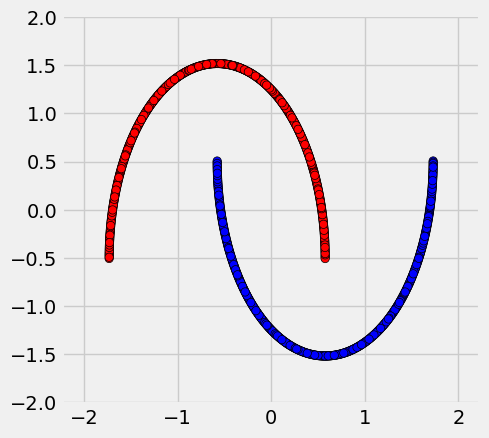

In [11]:
# First we generate and inspect some synthetic data, using one of the scikit-learn convenience
# functions to create a fairly tricky source distribution.
#
# Experiment with different amounts of noise to see how it affects the data.

X, y = skl.datasets.make_moons(n_samples=1000, noise=0.0001, random_state=0)
X = StandardScaler().fit_transform(X)
scatterplot_binary_data(X, y)

### 💡 Note: the synthetic dataset

`make_moons` makes two interleaving half-circles. They are not linearly separable, but they are perfectly separable by a curve. `noise=0.0001` means the moons are essentially noise-free. `StandardScaler` rescales each feature to zero mean and unit variance. This matters for distance-based (k-NN) and kernel (RBF) methods, which treat all axes equally (compare the feature rescaling in Lab 2).

👉 Try `noise=0.2` or `0.3`. The classes then overlap and the differences between non-linear classifiers appear (see the Q1 note).

,fpr_at_total_recall,precision,recall,f1,accuracy
Nearest Neighbors,0.000000,1.000000,1.000000,1.000000,1.000
Logistic,0.334646,0.894309,0.894309,0.894309,0.896
Linear SVM,0.330709,0.876494,0.894309,0.885312,0.886
RBF SVM,0.000000,1.000000,1.000000,1.000000,1.000
Decision Tree,0.003937,0.995951,1.000000,0.997972,0.998


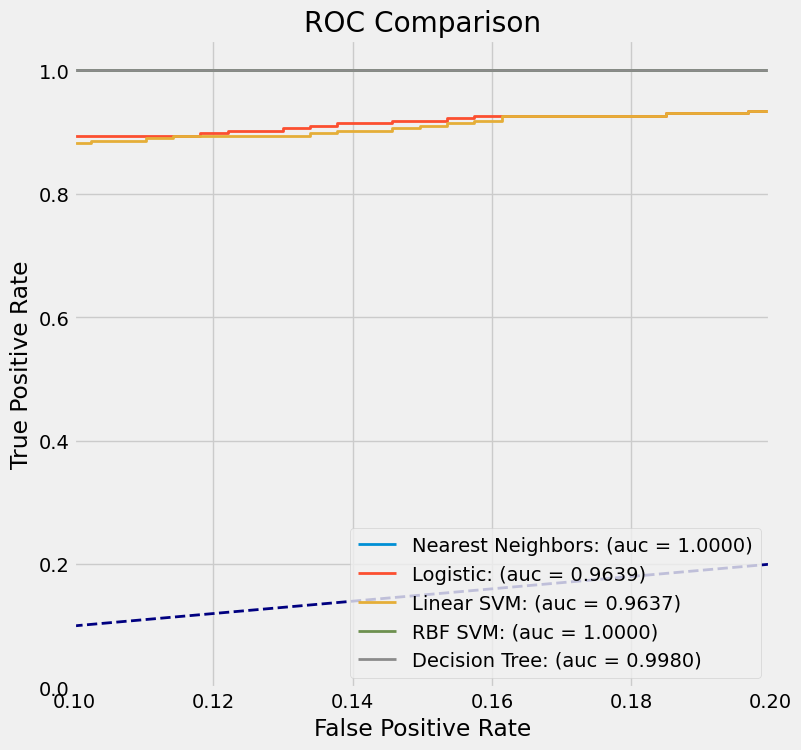

In [12]:
# Split the data into training and test sets (50/50), using another sklearn convenience function.
X_train, X_test, y_train, y_test = skl.model_selection.train_test_split(X, y, test_size=.5, random_state=0)

# Run this data through our classifiers, evaluating the ROC for each.
results_synthetic = evaluate_classifiers_ROC(classifiers, X_train, y_train, X_test, y_test)

# Show the result metrics and the ROC curves.
xlim = [0.1, 0.2]
ylim = [0.0, 1.05]
plot_ROCs(results_synthetic, xlim, ylim)
show_classifier_metrics(results_synthetic, y_test)

### 🔍 Interpreting the synthetic results

| Classifier | AUC | TPR at FPR=0.15 | FPR at total recall | Accuracy |
|---|---|---|---|---|
| Nearest Neighbors | 1.000 | 1.000 | 0.000 | 1.000 |
| Logistic | 0.964 | 0.919 | 0.335 | 0.896 |
| Linear SVM | 0.964 | 0.911 | 0.331 | 0.886 |
| RBF SVM | 1.000 | 1.000 | 0.000 | 1.000 |
| Decision Tree | 0.998 | 1.000 | 0.004 | 0.998 |

*(verified locally with the notebook's settings)*

- The **linear** models cannot follow the curved boundary, so they plateau around 89% accuracy and need a 33% false-alarm rate to catch every positive.
- k-NN and the RBF SVM separate the noise-free moons perfectly.
- The ROC plot is zoomed to `xlim=[0.1, 0.2]`, the region needed for Q1.

In [13]:
#
# Quiz: Which classifier has the highest TPR for an FPR of 15%? (hint: change the axis limits!)
#
# Provide your answer in the function 'question_1' in the lab module ('lab_3.py').

### 🛠️ How to answer Question 1 (highest TPR at FPR = 15%)

1. In the plot cell, set `xlim = [0.1, 0.2]` (already done) or `[0.14, 0.16]` and read which curve is highest at FPR = 0.15. Or compute it exactly with the optional helper below, which interpolates each ROC curve: `np.interp(0.15, fpr, tpr)`.
2. Put the classifier's *dictionary key* (the exact string) in `question_1()`:
```python
def question_1():
    return "Nearest Neighbors"
```

⚠️ **Teaching note on ambiguity.**
- With the current `noise=0.0001`, **k-NN, RBF SVM and the decision tree all reach TPR = 1.0** at FPR = 15%, so the plot shows a tie.
- With realistic noise, k-NN is the clear winner (verified): noise 0.2 → k-NN 0.992 vs RBF 0.988 vs tree 0.970; noise 0.3 → k-NN 0.944 vs RBF 0.935 vs tree 0.910.
- So **"Nearest Neighbors"** is the robust answer, which matches `lab_3.py`. Reset `noise` to the original value before moving on.

In [ ]:
# Optional helper added for learning: TPR of each classifier at FPR = 15% (Question 1)
for name, r in results_synthetic.items():
    print(f"{name:18s} TPR@FPR=0.15 = {np.interp(0.15, r['fpr'], r['tpr']):.4f}   AUC = {r['roc_auc']:.4f}")

In [14]:
#
# This is Part 2: Real Data
#

In [15]:
# Load up one of the standard datasets provided by the SciKit-Learn package.
data = skl.datasets.load_breast_cancer()

# In this data set, a label of '0' signifies malignant growth, and '1' signifies benign.
print("Target names: " + str(data.target_names))
print("\nDataset description:\n")
print(data.DESCR)

X_real = data.data
# Scale each feature to be 0-mean with variance 1.  Strictly speaking this should
# be done by fitting the transform to the training set and using that fit to
# normalize both the training and test data (rather than incroporating the test
# data into the computation of the fit).
X_real = StandardScaler().fit_transform(X_real)

# In this dataset, 'malignant' is coded with 0, but for ROC analysis it is
# a little more convenient to think of detection, i.e. 'present' vs 'not present',
# and so we will adjust the data so that 1 codes for 'malignant' (which we are
# trying to detect).
y_real = 1 - data.target

Target names: ['malignant' 'benign']

Dataset description:

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, 

### 💡 Note: the breast-cancer dataset (Wisconsin diagnostic)

- 569 tumours, 30 numeric features (radius, texture, etc.).
- sklearn codes malignant = 0. The cell flips the labels (`y_real = 1 - data.target`) so that **1 = malignant = the class we want to detect**. ROC "positives" are then cancers. About **37%** of the samples are malignant.
- ⚠️ The comment in the cell is right: fitting `StandardScaler` on *all* data before splitting **leaks** test-set statistics (mean and variance) into training. The correct pattern is `scaler.fit(X_train)`, then `scaler.transform(X_train)` and `scaler.transform(X_test)`, or a `make_pipeline(StandardScaler(), model)` as in Ex. 3. Here the effect is tiny, but it is a classic mistake to avoid (handout-04 slides 34–37).

,fpr_at_total_recall,precision,recall,f1,accuracy
Nearest Neighbors,1.000000,0.957447,0.891089,0.923077,0.947368
Logistic,0.375000,0.970000,0.960396,0.965174,0.975439
Linear SVM,0.206522,0.941176,0.950495,0.945813,0.961404
RBF SVM,0.217391,0.969697,0.950495,0.960000,0.971930
Decision Tree,1.000000,0.934783,0.851485,0.891192,0.926316


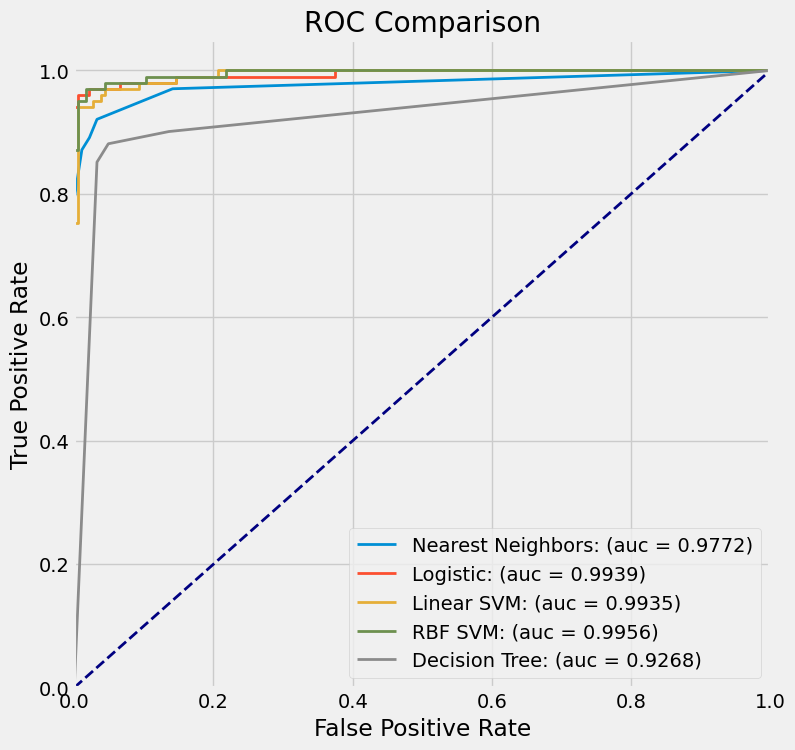

In [16]:
# Again we split the data into training and test sets, 50/50.
X_train, X_test, y_train, y_test = skl.model_selection.train_test_split(X_real, y_real, test_size=.5, random_state=0)

# We push this data through the functions defined above to compute metrics and plot ROCs.
results_real_data = evaluate_classifiers_ROC(classifiers, X_train, y_train, X_test, y_test)
plot_ROCs(results_real_data)
show_classifier_metrics(results_real_data, y_test)

### 🔍 Interpreting the real-data results (verified)

| Classifier | AUC | FPR at total recall | Accuracy |
|---|---|---|---|
| Nearest Neighbors | 0.977 | 1.000 | 0.947 |
| Logistic | 0.994 | 0.375 | 0.975 |
| **Linear SVM** | 0.994 | **0.207** | 0.961 |
| RBF SVM | 0.996 | 0.217 | 0.972 |
| Decision Tree | 0.927 | 1.000 | 0.926 |

- **The ranking flips compared with the synthetic data.** This 30-dimensional data is close to linearly separable, so the linear models do very well, and k-NN suffers from the curse of dimensionality. That is No Free Lunch again.
- **Different metrics crown different winners.** Logistic has the best accuracy, RBF SVM the best AUC, and the Linear SVM the best *FPR at total recall*. Choose the metric that matches the application (handout-04 slides 14–17).
- k-NN and the tree have FPR at total recall = 1.0: their few, coarse score values mean that the only threshold catching *every* cancer flags *everyone*.

In [17]:
# There is a problem with the approach we've taken above: it considers the two
# classes ('benign' & 'malignant') equally important (in the sense that the
# base rate for classification corresponds to the relative prevalance of
# each class in the training set).
#
# We want to be sure to detect malignancy, and so errors in classification of
# (true) malignant samples should count for more than errors in classification
# of benign samples, even if malignancy is less common than benignity.
#
# In the next cell we use class weights to influence our classifiers in this way.
# We will only evaluate the Linear SVM classifier, as it got the best performance
# in the 'fpr at 100% recall' rate.

### 💡 Concept note: class weights (cost-sensitive learning)

The SVM minimises $\frac12\lVert\mathbf w\rVert^2+C\sum_i \xi_i$, where $\xi_i$ is the hinge loss of sample $i$. With `class_weight={1: w}`, the penalty for errors on malignant samples becomes $w\,C\,\xi_i$. The optimiser then moves the boundary to protect positives and accepts more false positives in return.
- `'balanced'` sets weights inversely proportional to class frequency: $w_c = n/(2\,n_c)$.
- `weights = [1.05, 1.10, …, 1.50]`, so the notebook sweeps 10 manual weights for class 1.

Class weights change the **trained model**, not just the threshold, so they can genuinely improve the high-recall part of the ROC curve.

In [18]:
# Set up another set of classifiers, this time with class weights.

classifiers_w = {
    # The default is no class weights, which is the same as setting a weight of 1 on every class.
    'SVM-no_weight': SVC(kernel="linear", class_weight=None),
    # 'balanced' is a special option which sets weights to offset any disparity in prevalence in the training data.
    'SVM-balanced':  SVC(kernel="linear", class_weight='balanced'),
}

# We will add in a set of classifiers with numerically set weights for class 1---malignant.
# These weights are greater than 1, so they increase the importance of this class.
weights = [1 + 0.05*x for x in range(1,11)]

for w in weights:
    classifier_name = ('SVM-weight-%0.2f' % w)
    classifiers_w[classifier_name] = SVC(kernel="linear", class_weight={1: w})

,fpr_at_total_recall,precision,recall,f1,accuracy
SVM-no_weight,0.206522,0.941176,0.950495,0.945813,0.961404
SVM-balanced,0.146739,0.923810,0.960396,0.941748,0.957895
SVM-weight-1.05,0.195652,0.932039,0.950495,0.941176,0.957895
SVM-weight-1.10,0.184783,0.932039,0.950495,0.941176,0.957895
SVM-weight-1.15,0.168478,0.923077,0.950495,0.936585,0.954386
SVM-weight-1.20,0.163043,0.923077,0.950495,0.936585,0.954386
SVM-weight-1.25,0.163043,0.932039,0.950495,0.941176,0.957895
SVM-weight-1.30,0.163043,0.941176,0.950495,0.945813,0.961404
SVM-weight-1.35,0.146739,0.932039,0.950495,0.941176,0.957895
SVM-weight-1.40,0.152174,0.914286,0.950495,0.932039,0.950877


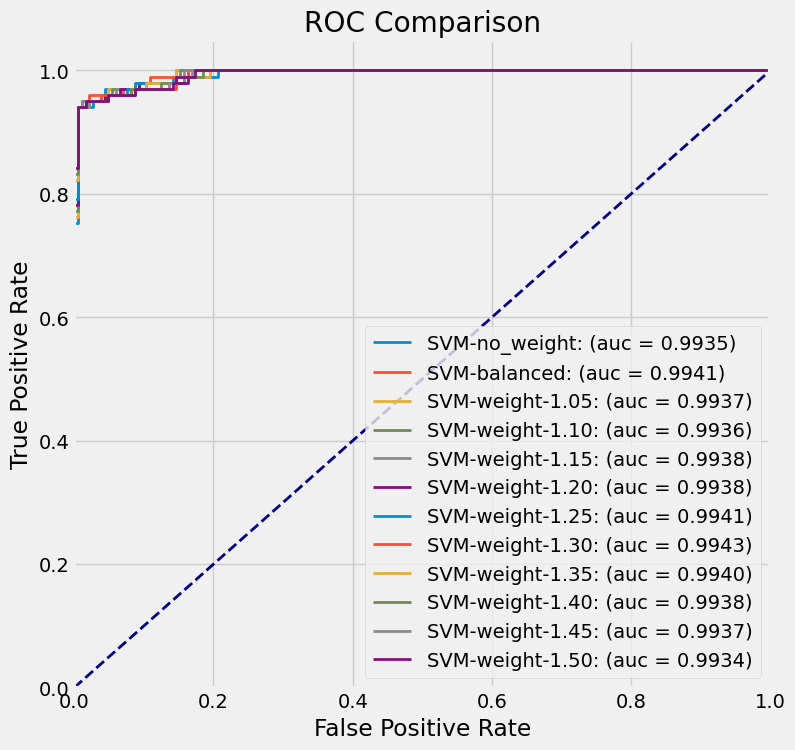

In [19]:
# Now we evaluate this new set of classifiers, which use the weights, and examine the performance.
results_real_data = evaluate_classifiers_ROC(classifiers_w, X_train, y_train, X_test, y_test)
xlim = [0.0, 1.0]
ylim = [0.0, 1.05]
plot_ROCs(results_real_data, xlim, ylim)
show_classifier_metrics(results_real_data, y_test)

### 🔍 Interpreting the class-weight results (verified)

| Model | FPR at total recall | Accuracy |
|---|---|---|
| no weight | 0.2065 | 0.961 |
| **balanced** | **0.1467** | 0.958 |
| 1.05 / 1.10 / 1.15 | 0.196 / 0.185 / 0.168 | |
| 1.20 / 1.25 / 1.30 | 0.163 | |
| **1.35** | **0.1467** (minimum) | 0.958 |
| 1.40 / 1.45 / 1.50 | 0.152 / 0.158 / 0.174 | |

Moderate up-weighting of malignant cases reduces false alarms at 100% recall by about 30% (0.207 → 0.147), at the cost of a tiny drop in accuracy. Too much weight (≥ 1.40) starts to hurt again. The relationship is not monotonic, which is why we **search** over the hyper-parameter rather than guess it.

In [20]:
#
# Quiz: Identify the numerical value of the weight which minimizes the fpr for total recall
#
# Provide your answer in the function 'question_2' in the lab module ('lab_3.py').

### 🛠️ How to answer Question 2

Read the `fpr_at_total_recall` column, find the smallest value among the **numeric** weights (`SVM-weight-x.xx`), and return that weight:
```python
def question_2():
    return 1.35
```
(`'balanced'` ties at 0.1467, but the question asks for a numerical value.)

To find it programmatically:
```python
best = min((r['fpr'][np.argmax(r['tpr'] >= 0.999)], name) for name, r in results_real_data.items() if 'weight-' in name)
```

## ✅ Lab 3 Ex. 1 key takeaways and self-check
1. A classifier outputs a **score**. The threshold turns it into labels, and the ROC curve shows every threshold at once.
2. AUC summarises ranking quality, but applications usually care about **one region** of the curve, e.g. FPR at 100% recall for cancer screening.
3. **No Free Lunch:** non-linear models won on the moons and linear models won on the 30-D cancer data.
4. Costs can be built into training with **class weights**. Tune them like any other hyper-parameter.
5. Fit pre-processing on training data only, to avoid leakage.

*Self-check:* What does a point at (FPR=0.2, TPR=1.0) mean in words? Why can a classifier have the best accuracy but not the best FPR at total recall? Why does k-NN have only a few distinct threshold values?